In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
df=pd.read_json('Sarcasm_Headlines_Dataset.json',lines=True)

In [52]:
df.head()

,article_link,headline,is_sarcastic
0,https://www.huffingtonpost.com/entry/versace-b...,former versace store clerk sues over secret 'b...,0
1,https://www.huffingtonpost.com/entry/roseanne-...,the 'roseanne' revival catches up to our thorn...,0
2,https://local.theonion.com/mom-starting-to-fea...,mom starting to fear son's web series closest ...,1
3,https://politics.theonion.com/boehner-just-wan...,"boehner just wants wife to listen, not come up...",1
4,https://www.huffingtonpost.com/entry/jk-rowlin...,j.k. rowling wishes snape happy birthday in th...,0


In [53]:
df.shape

(26709, 3)

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26709 entries, 0 to 26708
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   article_link  26709 non-null  object
 1   headline      26709 non-null  object
 2   is_sarcastic  26709 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 626.1+ KB


In [55]:
df.describe()

,is_sarcastic
count,26709.000000
mean,0.438953
std,0.496269
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [56]:
print('Rows and columns:', df.shape)
print('Data types:')
print(df.dtypes)
print('Class counts and percentages:')
print(pd.DataFrame({'count':df['is_sarcastic'].value_counts().sort_index(), 'percent':df['is_sarcastic'].value_counts(normalize=True).sort_index().mul(100).round(2)}))

Rows and columns: (26709, 3)
Data types:
article_link    object
headline        object
is_sarcastic     int64
dtype: object
Class counts and percentages:
              count  percent
is_sarcastic                
0             14985     56.1
1             11724     43.9


In [57]:
df.isnull().sum()

,0
article_link,0
headline,0
is_sarcastic,0


In [87]:
df.duplicated().sum()

np.int64(0)

In [59]:
df=df.drop_duplicates()

In [60]:
print('Shape after cleaning:',df.shape)
print('Remaining nulls:',df.isna().sum().to_dict())
print('Remaining exact duplicates:',df.duplicated().sum())
print('Empty headlines:',df['headline'].astype(str).str.strip().eq('').sum())

Shape after cleaning: (26708, 3)
Remaining nulls: {'article_link': 0, 'headline': 0, 'is_sarcastic': 0}
Remaining exact duplicates: 0
Empty headlines: 0


In [61]:
df['is_sarcastic'].value_counts()

,count
is_sarcastic,
0,14984
1,11724


In [62]:
from urllib.parse import urlparse

df['headline_word_count'] = df['headline'].fillna('').astype(str).str.split().str.len()
df['headline_char_count'] = df['headline'].fillna('').astype(str).str.len()
def get_source(url):
    host = urlparse(str(url)).netloc.lower().removeprefix('www.')
    return host if host else 'unknown'
df['article_source'] = df['article_link'].apply(get_source)
print(df[['headline','headline_word_count','headline_char_count','article_source','is_sarcastic']].head())
print(df[['headline_word_count','headline_char_count']].describe())

                                            headline  headline_word_count  \
0  former versace store clerk sues over secret 'b...                   12   
1  the 'roseanne' revival catches up to our thorn...                   14   
2  mom starting to fear son's web series closest ...                   14   
3  boehner just wants wife to listen, not come up...                   13   
4  j.k. rowling wishes snape happy birthday in th...                   11   

   headline_char_count         article_source  is_sarcastic  
0                   78     huffingtonpost.com             0  
1                   84     huffingtonpost.com             0  
2                   79     local.theonion.com             1  
3                   84  politics.theonion.com             1  
4                   64     huffingtonpost.com             0  
       headline_word_count  headline_char_count
count         26708.000000         26708.000000
mean              9.846039            60.911862
std               3.1

In [63]:
q1,q3=df['headline_word_count'].quantile([.25,.75])
iqr=q3-q1
upper=q3+1.5*iqr
long=df[df['headline_word_count']>upper]
print(f'Word-count IQR upper fence: {upper:.1f}; flagged headlines: {len(long)}')
print('Longest headlines:')
print(df.nlargest(10,'headline_word_count')[['headline','headline_word_count','is_sarcastic']].to_string(index=False))
print('Decision: retain length outliers pending manual content review; do not drop solely on IQR.')

Word-count IQR upper fence: 18.0; flagged headlines: 183
Longest headlines:
                                                                                                                                                                                                                                                      headline  headline_word_count  is_sarcastic
                 elmore leonard, modern prose master, noted for his terse prose style and for writing about things perfectly and succinctly with a remarkable economy of words, unfortunately and sadly expired this gloomy tuesday at the age of 87 years old                   39             1
                          occasionally you realize someone you thought was a dear friend is actually a foe, their true character finally revealed. but how do you forgive the unforgivable? here are my 10 steps to handling betrayal with elegance and grace.                   38             0
                '12 years a slave,' 'captain phillips,

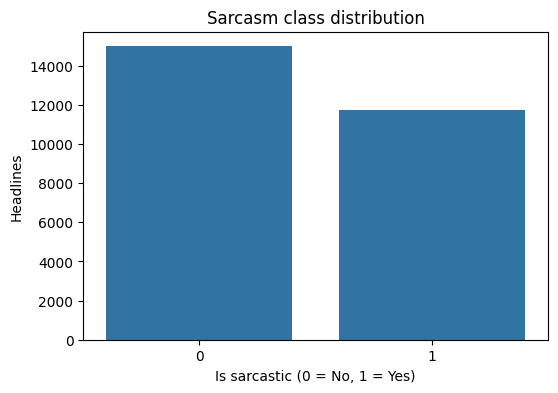

In [64]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='is_sarcastic')
plt.title('Sarcasm class distribution');plt.xlabel('Is sarcastic (0 = No, 1 = Yes)');plt.ylabel('Headlines');plt.show()

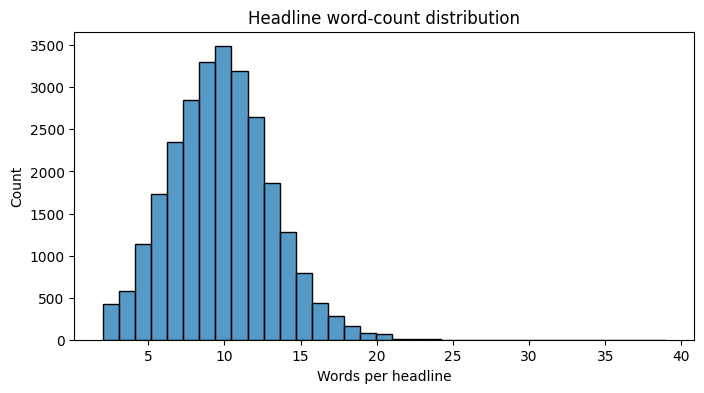

In [65]:
plt.figure(figsize=(8,4))
sns.histplot(data=df,x='headline_word_count',bins=35)
plt.title('Headline word-count distribution');plt.xlabel('Words per headline');plt.show()

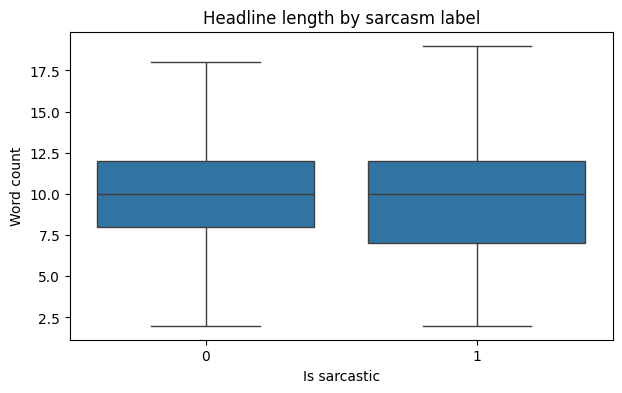

In [66]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df,x='is_sarcastic',y='headline_word_count',showfliers=False)
plt.title('Headline length by sarcasm label');plt.xlabel('Is sarcastic');plt.ylabel('Word count');plt.show()

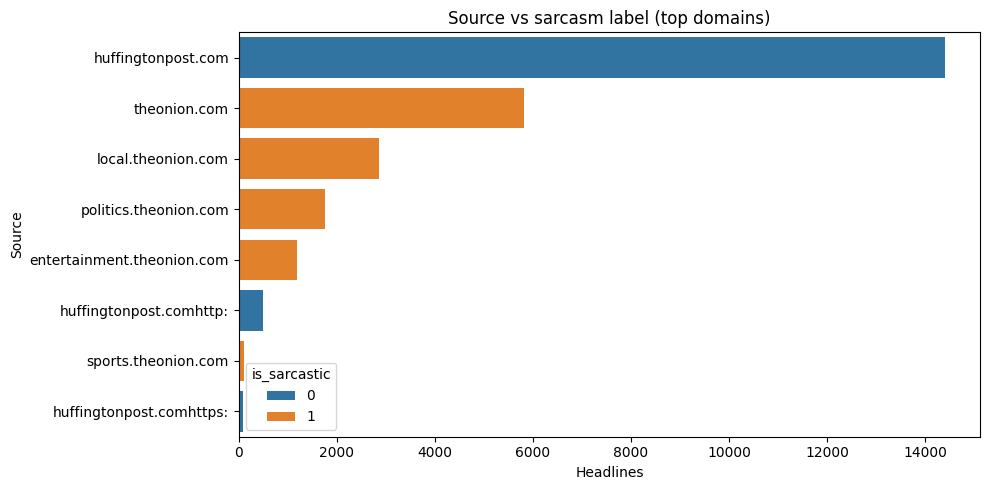

In [67]:
top_sources=df['article_source'].value_counts().head(8).index
source_df=df[df['article_source'].isin(top_sources)]
plt.figure(figsize=(10,5))
sns.countplot(data=source_df,y='article_source',hue='is_sarcastic',order=top_sources)
plt.title('Source vs sarcasm label (top domains)');plt.xlabel('Headlines');plt.ylabel('Source');plt.tight_layout();plt.show()

In [68]:
counts=df['is_sarcastic'].value_counts().sort_index()
pct=df['is_sarcastic'].value_counts(normalize=True).sort_index().mul(100)
means=df.groupby('is_sarcastic')['headline_word_count'].mean()
med=df['headline_word_count'].median()
print(f'1. Class balance: {counts.to_dict()} headlines; percentages: {pct.round(1).to_dict()}.')
print(f'2. Data quality: {df.isna().sum().sum()} missing cells, {df.duplicated().sum()} exact duplicate rows, and {df.headline.eq("").sum()} empty headline strings after cleaning.')
print(f'3. Headline length: median {med:.1f} words; maximum {df.headline_word_count.max()} words; {len(long)} above the IQR upper fence ({upper:.1f}).')
print(f'4. By label, average word count: non-sarcastic {means.get(0,float("nan")):.2f}; sarcastic {means.get(1,float("nan")):.2f}.')
print('5. Leading article domains (count):',df.article_source.value_counts().head(5).to_dict())
print('Source-level sarcasm rate (top domains):')
print(df[df.article_source.isin(top_sources)].groupby('article_source')['is_sarcastic'].agg(['count','mean']).round(3))

1. Class balance: {0: 14984, 1: 11724} headlines; percentages: {0: 56.1, 1: 43.9}.
2. Data quality: 0 missing cells, 0 exact duplicate rows, and 0 empty headline strings after cleaning.
3. Headline length: median 10.0 words; maximum 39 words; 183 above the IQR upper fence (18.0).
4. By label, average word count: non-sarcastic 9.82; sarcastic 9.88.
5. Leading article domains (count): {'huffingtonpost.com': 14403, 'theonion.com': 5811, 'local.theonion.com': 2852, 'politics.theonion.com': 1767, 'entertainment.theonion.com': 1194}
Source-level sarcasm rate (top domains):
                            count  mean
article_source                         
entertainment.theonion.com   1194   1.0
huffingtonpost.com          14403   0.0
huffingtonpost.comhttp:       502   0.0
huffingtonpost.comhttps:       79   0.0
local.theonion.com           2852   1.0
politics.theonion.com        1767   1.0
sports.theonion.com           100   1.0
theonion.com                 5811   1.0


In [69]:
x=df['headline']
y=df['is_sarcastic']

In [70]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42)

In [71]:
np.unique(y_train)

array([0, 1])

In [72]:
y_train

,is_sarcastic
17711,0
24708,1
5394,1
23207,0
3429,0
...,...
21575,1
5390,1
860,0
15795,1


In [73]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Input,Embedding,LSTM,Dense
from keras.models import Sequential

In [74]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [75]:
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(x_train)

In [76]:
x_train_tokens = tokenizer.texts_to_sequences(x_train)
x_test_tokens = tokenizer.texts_to_sequences(x_test)

In [77]:
from keras.preprocessing.sequence import pad_sequences

In [78]:
vocab_size=5000
maxlen=250

In [79]:
x_train_seq=pad_sequences(x_train_tokens,maxlen=maxlen,padding='post',truncating='post')
x_test_seq=pad_sequences(x_test_tokens,maxlen=maxlen,padding='post',truncating='post')

In [80]:
model=Sequential([
    Input(shape=(maxlen,)),
    Embedding(input_dim=vocab_size,output_dim=32),
    LSTM(32,activation='tanh'),
    Dense(1,activation='sigmoid')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 32)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [82]:
history=model.fit(x_train_seq,y_train,epochs=5,validation_split=0.2,batch_size=256)

Epoch 1/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 24s 308ms/step - accuracy: 0.5594 - loss: 0.6867 - val_accuracy: 0.5583 - val_loss: 0.6863
Epoch 2/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 18s 272ms/step - accuracy: 0.5622 - loss: 0.6857 - val_accuracy: 0.5583 - val_loss: 0.6865
Epoch 3/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 19s 247ms/step - accuracy: 0.5622 - loss: 0.6857 - val_accuracy: 0.5583 - val_loss: 0.6870
Epoch 4/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 19s 285ms/step - accuracy: 0.5622 - loss: 0.6856 - val_accuracy: 0.5583 - val_loss: 0.6864
Epoch 5/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 16s 246ms/step - accuracy: 0.5622 - loss: 0.6856 - val_accuracy: 0.5583 - val_loss: 0.6871


In [83]:
loss,acc=model.evaluate(x_test_seq,y_test)

167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.5595 - loss: 0.6869


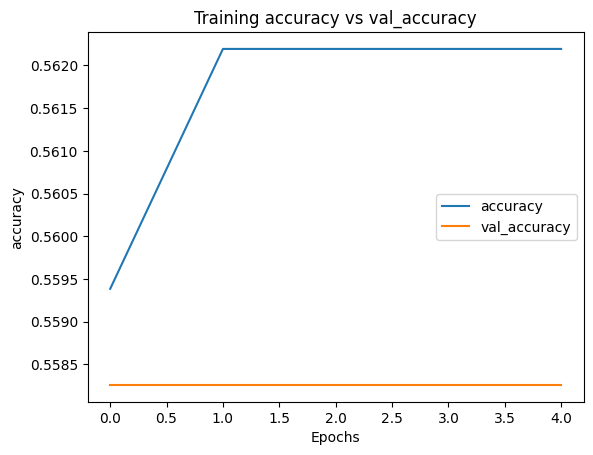

In [84]:
plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val_accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.title('Training accuracy vs val_accuracy')
plt.legend()
plt.show()

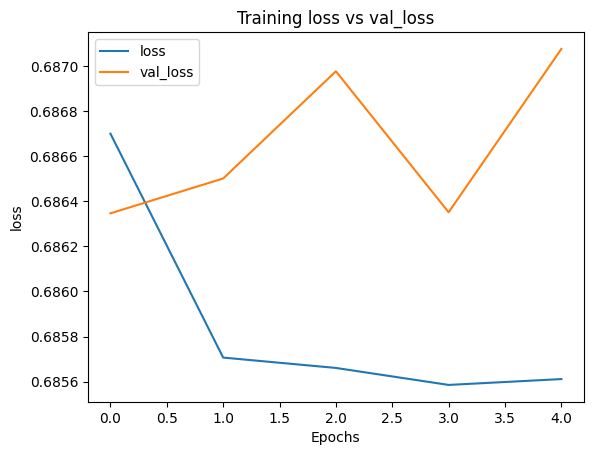

In [85]:
plt.plot(history.history['loss'],label='loss')
plt.plot(history.history['val_loss'],label='val_loss')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.title('Training loss vs val_loss')
plt.legend()
plt.show()

The forget gate allows an LSTM to decide which information to keep and which to forget from its previous memory, helping it focus on important information. Unlike a plain RNN, an LSTM can better preserve useful information over long sequences and reduce the vanishing gradient problem.